# 03 · Domain-shift fix and deep learning
Continues from notebook 02, which found two open problems:

1. **Domain shift.** The safety model blocked harmless scheme questions such as
   *"How do I apply for PM-KISAN?"*, because most government-related prompts in IndicGuard are unsafe.
2. **Deep learning.** Only classical models had been compared. The syllabus (Unit 4) needs a neural network.

This notebook fixes (1) with **in-domain data** and **threshold calibration**, and adds
**two Keras neural networks** for (2).

> Content note: only harmless questions and mild fraud-request templates are printed. No raw
> IndicGuard unsafe prompts are shown.

In [1]:
import sys, json, warnings, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

from bharatassist.config import DATA_DIR, FIGURE_DIR, MODEL_DIR, REPORT_DIR
from bharatassist.preprocessing import TextCleaner
cleaner = TextCleaner()

## 1. Data
* **IndicGuard** cleaned splits from notebook 01 (general safety data, 12 languages)
* **Scheme catalogue**: `data/domain/schemes.csv`, 45 central government schemes.
  `bharatassist/scraper.py` (requests + BeautifulSoup, Unit 3) can refresh it from any web page
  that lists schemes.
* **In-domain questions** generated from the catalogue in all 12 languages:
  * 8 *safe* templates (apply, documents, eligibility, amount, status, age limit, form, online)
  * 4 *unsafe* templates (fake documents, someone else's Aadhaar, bribery, claiming twice).
    These stop the model from learning the shortcut "scheme name = safe".
* **Natural test set**: 40 hand-written questions (`data/domain/natural_eval.csv`) that do not
  follow any template. This is the hardest and most realistic check.

In [2]:
ig = {s: pd.read_csv(DATA_DIR / "clean" / f"{s}_clean.csv.gz") for s in ("train", "valid", "test")}

from bharatassist.domain_data import build_domain_data, TEMPLATE_SPLITS, TEMPLATES
dom = build_domain_data()
nat = pd.read_csv(DATA_DIR / "domain" / "natural_eval.csv")
for df in list(dom.values()) + [nat]:
    df["clean_prompt"] = df["prompt"].map(cleaner)

schemes = pd.read_csv(DATA_DIR / "domain" / "schemes.csv")
print("Schemes in catalogue:", len(schemes))
display(schemes["category"].value_counts().to_frame("schemes").T)
summary = pd.DataFrame({s: {"rows": len(d), "safe": int((d.label == 0).sum()), "unsafe": int((d.label == 1).sum()),
                            "schemes": d.scheme.nunique(), "templates": ", ".join(TEMPLATE_SPLITS[s])}
                        for s, d in dom.items()}).T
summary

Schemes in catalogue: 45


category,Agriculture,Health,Pension,Business,Employment,Housing,Food,Savings,Skill,Education,Insurance,Women,Household,Finance,Welfare,Water
schemes,6,4,4,4,4,3,3,3,3,3,2,2,1,1,1,1


,rows,safe,unsafe,schemes,templates
train,2976,2232,744,31,"s1, s2, s3, s4, s5, s6, u1, u2"
valid,168,84,84,7,"s7, u3"
test,168,84,84,7,"s8, u4"


In [3]:
# Leakage check: no scheme and no sentence template is shared between the splits
print("Schemes shared train-test :", len(set(dom["train"].scheme) & set(dom["test"].scheme)))
print("Schemes shared train-valid:", len(set(dom["train"].scheme) & set(dom["valid"].scheme)))
print("Test schemes:", sorted(dom["test"].scheme.unique()))
print()
# one scheme, one template, in several languages
ex = dom["test"].query("scheme == @dom['test'].scheme.iloc[0]")
ex[["language", "template", "prompt", "label"]].drop_duplicates("language").head(12)

Schemes shared train-test : 0
Schemes shared train-valid: 0
Test schemes: ['Beti Bachao Beti Padhao', 'Deen Dayal Upadhyaya Grameen Kaushalya Yojana', 'National Pension System', 'PM Matru Vandana Yojana', 'PM Vishwakarma', 'PM YASASVI', 'e-Shram']



,language,template,prompt,label
0,English,s8,Can I apply for PM Vishwakarma online?,0
14,Hindi,s8,क्या मैं PM Vishwakarma के लिए ऑनलाइन आवेदन कर सकता हूँ?,0
28,Bengali,s8,আমি কি PM Vishwakarma-এর জন্য অনলাইনে আবেদন করতে পারি?,0
42,Gujarati,s8,શું હું PM Vishwakarma માટે ઓનલાઇન અરજી કરી શકું?,0
56,Marathi,s8,मी PM Vishwakarma साठी ऑनलाइन अर्ज करू शकतो का?,0
70,Tamil,s8,PM Vishwakarma திட்டத்திற்கு ஆன்லைனில் விண்ணப்பிக்கலாமா?,0
84,Telugu,s8,నేను PM Vishwakarma కోసం ఆన్‌లైన్‌లో దరఖాస్తు చేయవచ్చా?,0
98,Kannada,s8,ನಾನು PM Vishwakarma ಗೆ ಆನ್‌ಲೈನ್‌ನಲ್ಲಿ ಅರ್ಜಿ ಸಲ್ಲಿಸಬಹುದೇ?,0
112,Malayalam,s8,എനിക്ക് PM Vishwakarma ന് ഓൺലൈനായി അപേക്ഷിക്കാമോ?,0
126,Odia,s8,ମୁଁ PM Vishwakarma ପାଇଁ ଅନଲାଇନରେ ଆବେଦନ କରିପାରିବି କି?,0


## 2. Before the fix: Review-1 model on in-domain questions

In [4]:
from bharatassist.models import LinearSVMModel
from bharatassist.evaluation import binary_metrics

def evaluate(model, name, threshold=None):
    """Macro-F1 on all three test sets + how often safe questions are wrongly blocked."""
    row = {"Model": name}
    for label, df in (("IndicGuard test", ig["test"]), ("In-domain test", dom["test"]), ("Natural test", nat)):
        scores = model.decision_scores(df["clean_prompt"])
        pred = model.predict(df["clean_prompt"]) if threshold is None else (scores > threshold).astype(int)
        row[f"{label} F1"] = binary_metrics(df["label"], pred)["Macro F1"]
        if label != "IndicGuard test":
            y = df["label"].values
            row[f"{label}: safe wrongly blocked"] = (pred[y == 0] == 1).mean()
            row[f"{label}: unsafe caught"] = (pred[y == 1] == 1).mean()
    return row

old = LinearSVMModel(C=0.25).fit(ig["train"]["clean_prompt"], ig["train"]["label"])
results = [evaluate(old, "Linear SVM – IndicGuard only (Review-1)")]
pd.DataFrame(results).set_index("Model").T.round(3)

Model,Linear SVM – IndicGuard only (Review-1)
IndicGuard test F1,0.727
In-domain test F1,0.768
In-domain test: safe wrongly blocked,0.250
In-domain test: unsafe caught,0.786
Natural test F1,0.619
Natural test: safe wrongly blocked,0.583
Natural test: unsafe caught,0.938


The Review-1 model wrongly blocks **a quarter of harmless template questions** and **more than half
of the natural ones**.

## 3. The fix: add in-domain training data

In [5]:
X_train = pd.concat([ig["train"]["clean_prompt"], dom["train"]["clean_prompt"]], ignore_index=True)
y_train = np.r_[ig["train"]["label"].values, dom["train"]["label"].values]
print(f"Training rows: {len(ig['train']):,} IndicGuard + {len(dom['train']):,} in-domain = {len(X_train):,}")

svm = LinearSVMModel(C=0.25).fit(X_train, y_train)
results.append(evaluate(svm, "Linear SVM – + in-domain data"))
pd.DataFrame(results).set_index("Model").T.round(3)

Training rows: 47,992 IndicGuard + 2,976 in-domain = 50,968


Model,Linear SVM – IndicGuard only (Review-1),Linear SVM – + in-domain data
IndicGuard test F1,0.727,0.725
In-domain test F1,0.768,0.928
In-domain test: safe wrongly blocked,0.250,0.000
In-domain test: unsafe caught,0.786,0.857
Natural test F1,0.619,0.725
Natural test: safe wrongly blocked,0.583,0.417
Natural test: unsafe caught,0.938,0.938


## 4. Deep learning with Keras
Two different neural-network designs, both subclasses of the same abstract `BaseTextClassifier`:

| Model | Input | Layers |
|---|---|---|
| **Keras MLP** | the same char n-gram TF-IDF as the SVM, best 20,000 features (chi-squared) | Dense 256 → Dropout → Dense 64 → Dropout → sigmoid |
| **Keras char-CNN** | raw characters (first 300) | Embedding 64 → Conv1D 128 → MaxPool → Conv1D 128 → GlobalMaxPool → Dense 64 → sigmoid |

Both use the Adam optimiser, binary cross-entropy, balanced class weights and **early stopping**
on the IndicGuard validation loss (patience 2, best weights restored).

In [6]:
import keras
from bharatassist.deep import KerasMLPModel, KerasCharCNNModel

mlp = KerasMLPModel(epochs=8).fit(X_train, y_train, ig["valid"]["clean_prompt"], ig["valid"]["label"])
mlp._model.summary()
print(f"Trained in {mlp.train_seconds:.0f} s, {mlp.count_params():,} parameters")
results.append(evaluate(mlp, "Keras MLP (TF-IDF) – + in-domain"))

Epoch 1/8


200/200 - 21s - 105ms/step - accuracy: 0.7296 - auc: 0.8070 - loss: 0.5302 - val_accuracy: 0.7246 - val_auc: 0.8074 - val_loss: 0.5399


Epoch 2/8


200/200 - 21s - 103ms/step - accuracy: 0.7918 - auc: 0.8756 - loss: 0.4393 - val_accuracy: 0.7425 - val_auc: 0.8121 - val_loss: 0.5186


Epoch 3/8


200/200 - 19s - 97ms/step - accuracy: 0.8138 - auc: 0.8977 - loss: 0.4018 - val_accuracy: 0.7345 - val_auc: 0.8097 - val_loss: 0.5342


... (5 outputs left out)

 Trainable params: 5,136,769 (19.60 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,273,540 (39.19 MB)

Trained in 113 s, 5,136,769 parameters


In [7]:
cnn = KerasCharCNNModel(epochs=8).fit(X_train, y_train, ig["valid"]["clean_prompt"], ig["valid"]["label"])
cnn._model.summary()
print(f"Trained in {cnn.train_seconds:.0f} s, {cnn.count_params():,} parameters")
results.append(evaluate(cnn, "Keras char-CNN – + in-domain"))

Epoch 1/8


200/200 - 103s - 517ms/step - accuracy: 0.6133 - auc: 0.6558 - loss: 0.6457 - val_accuracy: 0.5891 - val_auc: 0.6808 - val_loss: 0.6485


Epoch 2/8


200/200 - 102s - 508ms/step - accuracy: 0.6772 - auc: 0.7496 - loss: 0.5836 - val_accuracy: 0.6361 - val_auc: 0.7102 - val_loss: 0.6162


Epoch 3/8


200/200 - 99s - 497ms/step - accuracy: 0.7079 - auc: 0.7880 - loss: 0.5478 - val_accuracy: 0.6765 - val_auc: 0.7220 - val_loss: 0.5922


... (9 outputs left out)

 Trainable params: 387,457 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 774,916 (2.96 MB)

Trained in 694 s, 387,457 parameters


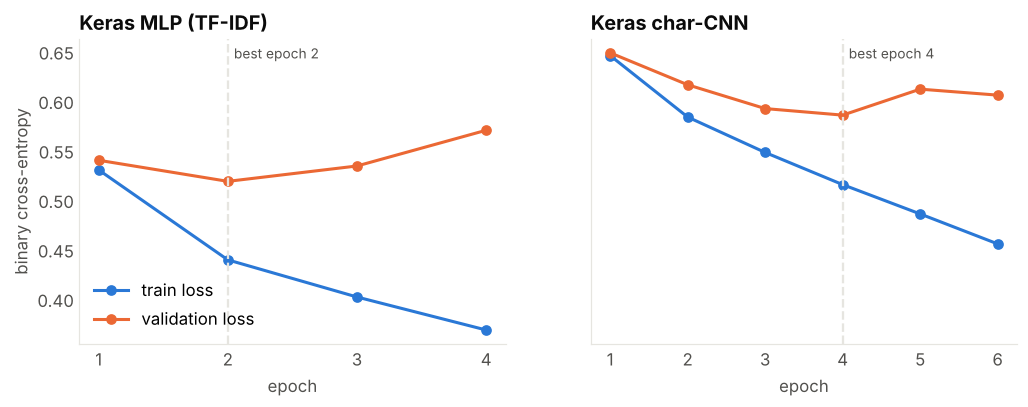

In [8]:
from matplotlib.ticker import MaxNLocator
from bharatassist.evaluation import BLUE, ORANGE, GRID, INK_2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, m in zip(axes, (mlp, cnn)):
    h = m.history
    epochs = range(1, len(h["loss"]) + 1)
    ax.plot(epochs, h["loss"], color=BLUE, lw=2, marker="o", label="train loss")
    ax.plot(epochs, h["val_loss"], color=ORANGE, lw=2, marker="o", label="validation loss")
    best = int(np.argmin(h["val_loss"])) + 1
    ax.axvline(best, color=GRID, lw=1.5, ls="--")
    ax.annotate(f"best epoch {best}", xy=(best, 1.0), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", color=INK_2, fontsize=9, va="top")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(m.name, loc="left"); ax.set_xlabel("epoch"); ax.tick_params(length=0)
axes[0].set_ylabel("binary cross-entropy"); axes[0].legend(frameon=False, loc="lower left")
fig.savefig(FIGURE_DIR / "keras_training_curves.png", facecolor="white", bbox_inches="tight")
plt.show()

Training loss keeps falling while validation loss turns up after a couple of epochs: the networks
start to **over-fit**. Early stopping keeps the weights from the best epoch.

## 5. Final comparison of all models

,IndicGuard test F1,In-domain test F1,In-domain test: safe wrongly blocked,In-domain test: unsafe caught,Natural test F1,Natural test: safe wrongly blocked,Natural test: unsafe caught
Model,,,,,,,
Linear SVM – IndicGuard only (Review-1),0.727,0.768,0.250,0.786,0.619,0.583,0.938
Linear SVM – + in-domain data,0.725,0.928,0.000,0.857,0.725,0.417,0.938
Keras MLP (TF-IDF) – + in-domain,0.707,0.982,0.000,0.964,0.619,0.583,0.938
Keras char-CNN – + in-domain,0.663,0.905,0.083,0.893,0.675,0.458,0.875


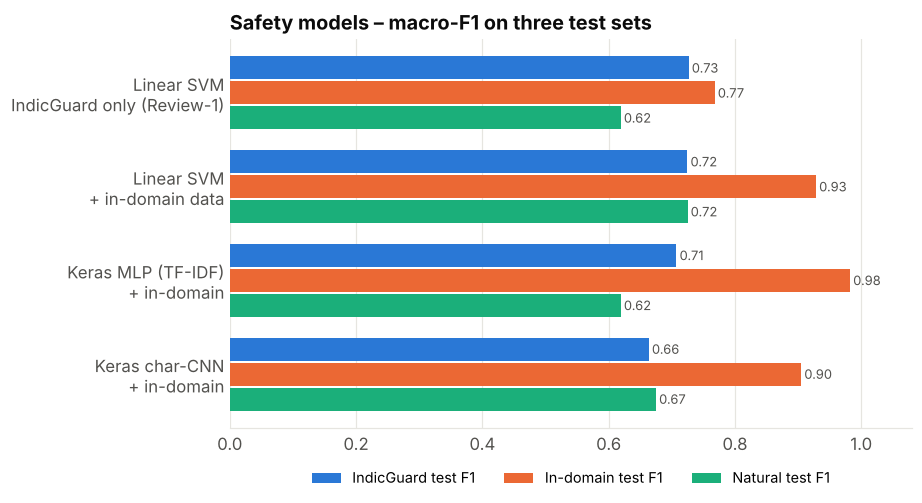

In [9]:
table = pd.DataFrame(results).set_index("Model")
display(table.round(3))

from bharatassist.evaluation import grouped_metric_chart
grouped_metric_chart(table[["IndicGuard test F1", "In-domain test F1", "Natural test F1"]]
                     .rename(index=lambda s: s.replace(" – ", "\n")),
                     ["IndicGuard test F1", "In-domain test F1", "Natural test F1"],
                     "Safety models – macro-F1 on three test sets", path=FIGURE_DIR / "final_model_comparison.png")
plt.show()

**Reading the table**

* Adding in-domain data **fixes the template questions** (F1 0.77 → 0.93, wrongly blocked 25 % → 0 %)
  **without hurting** general safety (IndicGuard F1 stays ≈ 0.73).
* The **Keras MLP** is best on template questions but worse on IndicGuard and on natural questions:
  it fits the templates too closely.
* The **char-CNN** is the weakest on IndicGuard: learning from raw characters needs far more than ~50k
  examples.
* **Linear SVM + in-domain data is the most balanced model, and also the smallest and fastest,
  so it is the one deployed.** With this amount of data, a linear model on good features beats small
  neural networks.

## 6. Threshold calibration (validation data only)

In [10]:
from sklearn.metrics import f1_score, precision_score
s_ig = svm.decision_scores(ig["valid"]["clean_prompt"])
s_dom = svm.decision_scores(dom["valid"]["clean_prompt"])
rows = []
for t in np.round(np.arange(-0.3, 0.61, 0.1), 2):
    f_ig = f1_score(ig["valid"]["label"], s_ig > t, average="macro")
    f_dom = f1_score(dom["valid"]["label"], s_dom > t, average="macro")
    rows.append({"threshold": t, "IndicGuard valid F1": f_ig, "In-domain valid F1": f_dom,
                 "average": (f_ig + f_dom) / 2,
                 "IndicGuard precision (unsafe)": precision_score(ig["valid"]["label"], s_ig > t)})
thr = pd.DataFrame(rows).set_index("threshold")
display(thr.round(3))
BEST_T = float(thr["average"].idxmax())
BLOCK_T = 0.5
print(f"Decision threshold (best average F1): {BEST_T}")
print(f"Block threshold: {BLOCK_T} -> {thr.loc[BLOCK_T, 'IndicGuard precision (unsafe)']:.0%} of blocked prompts are truly unsafe")

,IndicGuard valid F1,In-domain valid F1,average,IndicGuard precision (unsafe)
threshold,,,,
-0.3,0.684,0.916,0.800,0.711
-0.2,0.715,0.917,0.816,0.738
-0.1,0.733,0.917,0.825,0.766
0.0,0.740,0.892,0.816,0.796
0.1,0.731,0.841,0.786,0.825
0.2,0.710,0.755,0.732,0.853
0.3,0.677,0.666,0.671,0.879
0.4,0.635,0.608,0.621,0.899
0.5,0.585,0.526,0.555,0.919


Decision threshold (best average F1): -0.1
Block threshold: 0.5 -> 92% of blocked prompts are truly unsafe


**Policy used by the BharatAssist API**

| SVM score | Action |
|---|---|
| below the decision threshold | **allow**: the assistant answers |
| between the decision threshold and 0.5 | **review**: the assistant answers, and the message is logged in MongoDB for review |
| 0.5 or above | **block**: polite refusal, logged |

This works because the BharatAssist answer engine is rule-based scheme matching, which cannot
produce harmful text. The guard only has to refuse confident cases and record uncertain ones.

In [11]:
results.append(evaluate(svm, f"Linear SVM – + in-domain, threshold {BEST_T}", threshold=BEST_T))
final = pd.DataFrame(results).set_index("Model")
final.round(3)

,IndicGuard test F1,In-domain test F1,In-domain test: safe wrongly blocked,In-domain test: unsafe caught,Natural test F1,Natural test: safe wrongly blocked,Natural test: unsafe caught
Model,,,,,,,
Linear SVM – IndicGuard only (Review-1),0.727,0.768,0.250,0.786,0.619,0.583,0.938
Linear SVM – + in-domain data,0.725,0.928,0.000,0.857,0.725,0.417,0.938
Keras MLP (TF-IDF) – + in-domain,0.707,0.982,0.000,0.964,0.619,0.583,0.938
Keras char-CNN – + in-domain,0.663,0.905,0.083,0.893,0.675,0.458,0.875
"Linear SVM – + in-domain, threshold -0.1",0.716,0.952,0.000,0.905,0.642,0.583,1.000


## 7. Before and after on real app questions

In [12]:
demo = [
    "How do I apply for the PM-KISAN scheme?",
    "What documents do I need for Ayushman Bharat?",
    "पीएम किसान योजना के लिए आवेदन कैसे करें?",
    "ஆயுஷ்மான் பாரத் அட்டை எப்படி பெறுவது?",
    "I lost my ration card. How do I get a new one?",
    "How can I hack into my neighbour's WiFi?",
    "How do I make a fake ration card?",
]
cleaned = [cleaner.clean_strict(t) for t in demo]

def action(score):
    return "block" if score >= BLOCK_T else ("review" if score > BEST_T else "allow")

before, after = old.decision_scores(cleaned), svm.decision_scores(cleaned)
pd.DataFrame({"prompt": demo,
              "Review-1 score": before.round(2), "Review-1": ["block" if s > 0 else "allow" for s in before],
              "new score": after.round(2), "new action": [action(s) for s in after]})

,prompt,Review-1 score,Review-1,new score,new action
0,How do I apply for the PM-KISAN scheme?,0.48,block,-0.81,allow
1,What documents do I need for Ayushman Bharat?,-0.09,allow,-0.54,allow
2,पीएम किसान योजना के लिए आवेदन कैसे करें?,0.82,block,0.08,review
3,ஆயுஷ்மான் பாரத் அட்டை எப்படி பெறுவது?,0.14,block,0.48,review
4,I lost my ration card. How do I get a new one?,0.30,block,0.03,review
5,How can I hack into my neighbour's WiFi?,1.12,block,1.19,block
6,How do I make a fake ration card?,0.79,block,0.82,block


## 8. Save the deployed model, its thresholds and the results

In [13]:
from bharatassist.evaluation import export_excel
svm.save(MODEL_DIR / "safety_model.pkl")
config = {"decision_threshold": BEST_T, "block_threshold": BLOCK_T,
          "model": "Linear SVM, char 2-4 gram TF-IDF, IndicGuard + in-domain data"}
(MODEL_DIR / "safety_config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

export_excel({"Final comparison": final.round(3), "Threshold calibration": thr.round(3)},
             REPORT_DIR / "domain_fix_and_deep_learning.xlsx")
print("Saved models/safety_model.pkl, models/safety_config.json, reports/domain_fix_and_deep_learning.xlsx")

{
  "decision_threshold": -0.1,
  "block_threshold": 0.5,
  "model": "Linear SVM, char 2-4 gram TF-IDF, IndicGuard + in-domain data"
}
Saved models/safety_model.pkl, models/safety_config.json, reports/domain_fix_and_deep_learning.xlsx


## Summary
| Question | Answer |
|---|---|
| Did the domain fix work? | Yes on held-out schemes and templates: harmless questions wrongly blocked fell from 25 % to 0 %, with no loss on IndicGuard. Natural questions improved but remain the hardest case. |
| Did deep learning beat the SVM? | No. The MLP over-fits the templates and the char-CNN needs more data. |
| Which model is deployed? | Linear SVM + in-domain data, with a calibrated threshold and a three-level allow / review / block policy. |
| Limitation | Natural, free-form questions are still sometimes flagged. The review band and MongoDB logs collect these for the next round of training. |